# Modelo Multitarea Basado en Redes Neuronales Convolucionales para la Estimación de Edad y Género a partir de Rostros
---

# Teoría

## Introducción

Reconocer atributos faciales automáticamente es uno de los problemas clásicos de la visión por computador. Esto posee aplicaciones directas en Sistemas de control de accesso, seguridad biométrica, monitorio en entornos, etcétera

El objetivo central del proyecto es diseñar, entrenar y evaluar comparativamente arquitecturas de aprendizaje profundo para predecir de forma conjunta la edad y el género de un individuo a partir de una única imagen de su rostro.

El desarrollo se articulará en torno a la comparación de **tres modelos**:

1. **Modelo Especializado en Edad:** Backbone convolucional conectado a una cabeza densa de salida escalar, formulado como un problema de regresión continua optimizado mediante error cuadrático medio ($MSE$) o error absoluto ($L_1$).
2. **Modelo Especializado en Género:** Backbone convolucional idéntico o análogo, conectado a una cabeza de salida binaria (activación sigmoide), optimizado bajo entropía cruzada binaria ($BCE$).
3. **Modelo Multitarea (MTL):** Arquitectura con un tronco convolucional compartido (*shared representation*) que se bifurca en dos cabezas lineales diferenciadas: una rama de regresión para la edad y una rama de clasificación binaria para el género. <img src="https://i.imgur.com/53V0Kuc.jpeg" width=500px>



## Dataset Seleccionado

Se empleará el conjunto de datos **UTKFace** (distribuido en Kaggle), compuesto por más de 20.000 imágenes de rostros en condiciones no controladas. Los nombres de archivo codifican los atributos de cada imagen bajo el formato:

$$\texttt{[age]\_[gender]\_[race]\_[date\&time].jpg}$$

* **Edad:** Variable cuantitativa continua (rango de 0 a 116 años).
* **Género:** Variable cualitativa binaria (0: Masculino, 1: Femenino).

## Loss para redes multitarea

Investigando [1], se consiguió que, la forma más sencilla y común de combinar varias pérdidas es sumarlas. Sumar pérdidas significa sumar directamente varios valores de pérdida para calcular una pérdida total. Este enfoque resulta útil cuando se desea considerar por igual múltiples aspectos del rendimiento del modelo (En este caso, la precisión de la clasificación y la precisión de la regresión).

Visto matemáticamente, la función de Loss multitarea viene dada por:



$$L[\boldsymbol{\phi}] = \alpha L_{\text{edad}}[\boldsymbol{\phi}] + (1 - \alpha) L_{\text{género}}[\boldsymbol{\phi}]$$

# Librerias a utilizar

In [74]:
import os
import re
import kagglehub
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm
import torch.nn as nn
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# Muestreo

### Descarga del dataset y primer descarte

In [75]:
path = kagglehub.dataset_download("jangedoo/utkface-new")
print("Ruta base descargada:", path)

target_dir = None
for root, dirs, files in os.walk(path):
    jpg_files = [f for f in files if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    if len(jpg_files) > 20000:
        target_dir = root
        break

if target_dir is None:
    target_dir = path

print(f"Directorio de trabajo seleccionado: {target_dir}")

Ruta base descargada: /home/edwyn/.cache/kagglehub/datasets/jangedoo/utkface-new/versions/1
Directorio de trabajo seleccionado: /home/edwyn/.cache/kagglehub/datasets/jangedoo/utkface-new/versions/1/utkface_aligned_cropped/UTKFace


Para empezar se verifica que todas las imágenes estén nombradas correctamente, para este entrenamiento, esperamos que las imágenes estén nombrada de la forma `[age]_[gender]_[race]_[date&time].jpg`. Todos los datos que no cumplan con este requisito se descartan.

In [76]:
# Formato esperado: [age]_[gender]_[race]_[date&time].jpg
records = []
corrupted_files = []

# Expresión regular para validar el formato de 4 campos numéricos base
pattern = re.compile(r"^(\d+)_([01])_(\d+)_.*")

for fname in os.listdir(target_dir):
    if not fname.lower().endswith(('.jpg', '.jpeg', '.png')):
        continue

    match = pattern.match(fname)
    if match:
        age, gender, race = match.groups()
        records.append({
            "filepath": os.path.join(target_dir, fname),
            "filename": fname,
            "age": int(age),
            "gender": int(gender),
            "race": int(race)
        })
    else:
        parts = fname.split('_')
        if len(parts) >= 3 and parts[0].isdigit() and parts[1] in ['0', '1'] and parts[2].isdigit():
            records.append({
                "filepath": os.path.join(target_dir, fname),
                "filename": fname,
                "age": int(parts[0]),
                "gender": int(parts[1]),
                "race": int(parts[2])
            })
        else:
            corrupted_files.append(fname)

df = pd.DataFrame(records)

print(f"Total de muestras válidas: {len(df)}")
print(f"Muestras descartadas por nombres anómalos: {len(corrupted_files)}")

Total de muestras válidas: 23705
Muestras descartadas por nombres anómalos: 3


### Visualización inicial del dataset

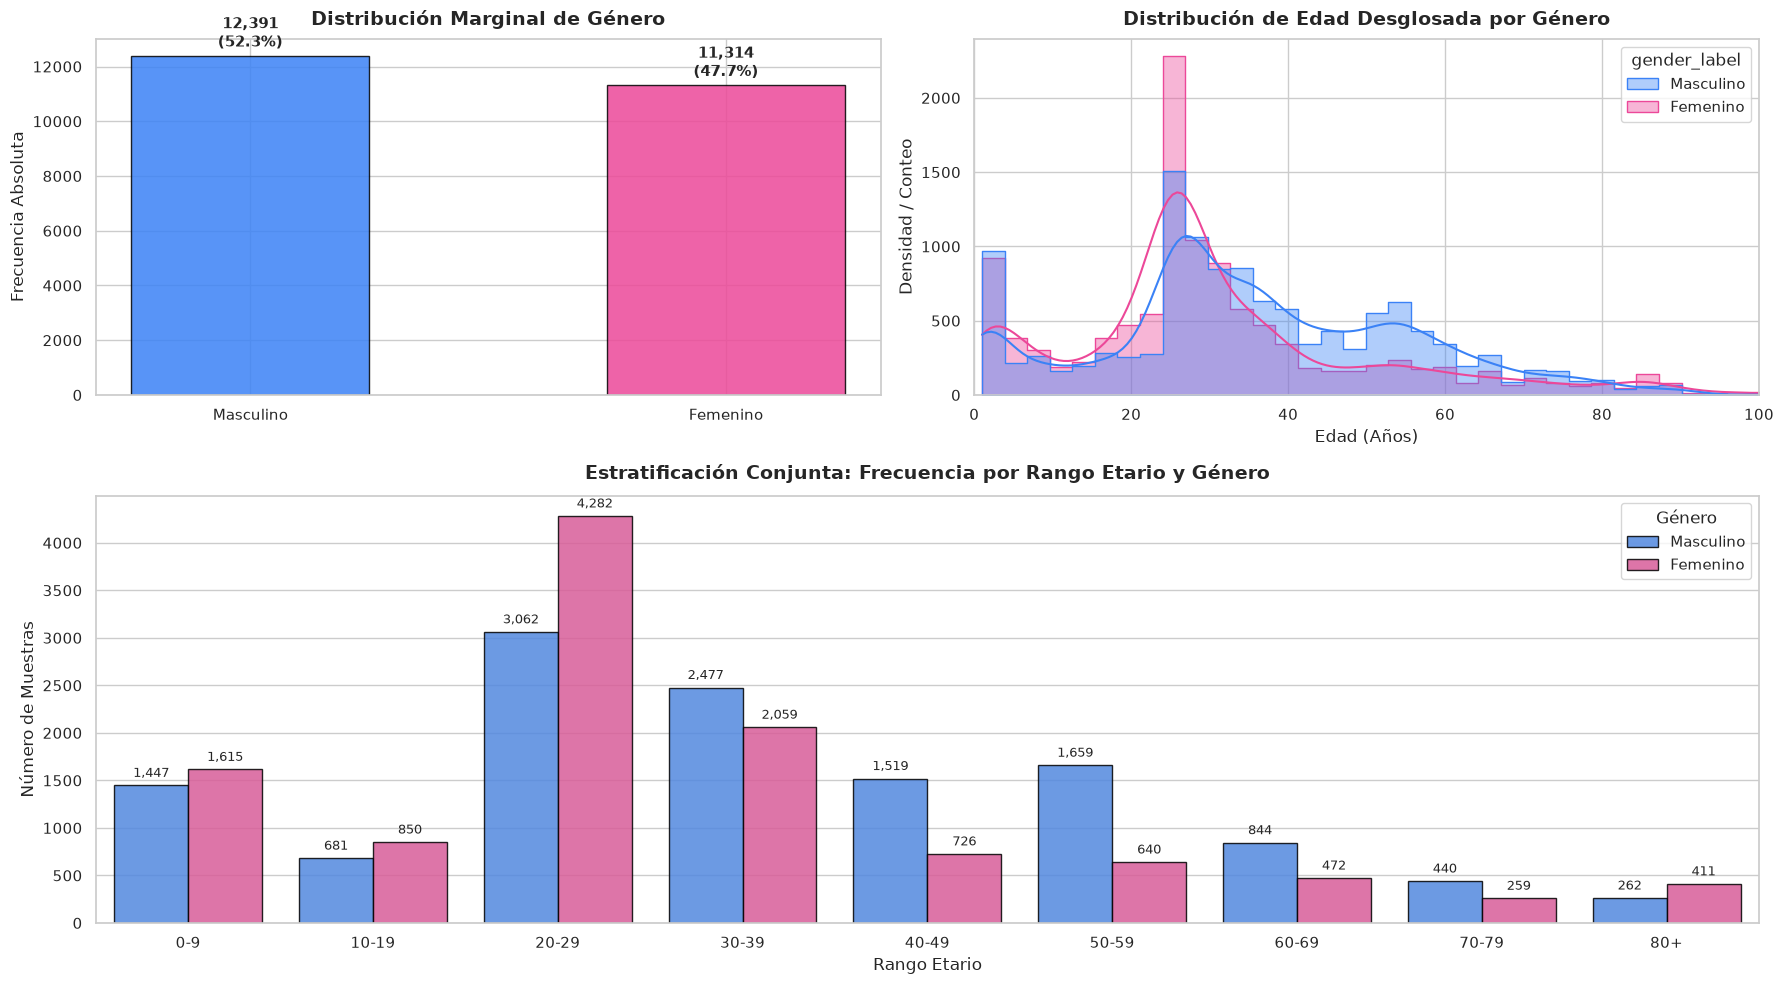

In [77]:
# Configurar estilo visual limpio
sns.set_theme(style="whitegrid")
fig = plt.figure(figsize=(18, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# Mapeo semántico para etiquetas legibles
df['gender_label'] = df['gender'].map({0: 'Masculino', 1: 'Femenino'})

# Bins de edad para análisis demográfico
age_bins = [0, 10, 20, 30, 40, 50, 60, 70, 80, 120]
age_labels = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80+']
df['age_bracket'] = pd.cut(df['age'], bins=age_bins, labels=age_labels, right=False)

# Gráfico Superior Izquierdo: Balance de Género
ax1 = fig.add_subplot(gs[0, 0])
gender_counts = df['gender_label'].value_counts()
colors = ['#3b82f6', '#ec4899']

bars = ax1.bar(gender_counts.index, gender_counts.values, color=colors, width=0.5, edgecolor='black', alpha=0.85)
ax1.set_title("Distribución Marginal de Género", fontsize=14, weight='bold', pad=10)
ax1.set_ylabel("Frecuencia Absoluta", fontsize=12)

# Anotación con porcentaje y conteo
total = len(df)
for bar in bars:
    height = bar.get_height()
    ax1.annotate(f"{height:,}\n({height/total:.1%})",
                 xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points",
                 ha='center', va='bottom', fontsize=11, weight='bold')

# Gráfico Superior Derecho: Histograma Continuo de Edad
ax2 = fig.add_subplot(gs[0, 1])
sns.histplot(
    data=df, x='age', hue='gender_label',
    palette={'Masculino': '#3b82f6', 'Femenino': '#ec4899'},
    element='step', kde=True, bins=40, ax=ax2, alpha=0.4
)
ax2.set_title("Distribución de Edad Desglosada por Género", fontsize=14, weight='bold', pad=10)
ax2.set_xlabel("Edad (Años)", fontsize=12)
ax2.set_ylabel("Densidad / Conteo", fontsize=12)
ax2.set_xlim(0, 100)

# Gráfico Inferior: Distribución Conjunta (Estratos Edad x Género)
ax3 = fig.add_subplot(gs[1, :])
sns.countplot(
    data=df, x='age_bracket', hue='gender_label',
    palette={'Masculino': '#3b82f6', 'Femenino': '#ec4899'},
    ax=ax3, edgecolor='black', alpha=0.85
)
ax3.set_title("Estratificación Conjunta: Frecuencia por Rango Etario y Género", fontsize=14, weight='bold', pad=12)
ax3.set_xlabel("Rango Etario", fontsize=12)
ax3.set_ylabel("Número de Muestras", fontsize=12)
ax3.legend(title="Género", frameon=True)

# Anotar conteos exactos sobre cada barra del gráfico conjunto
for p in ax3.patches:
    h = p.get_height()
    if h > 0:
        ax3.annotate(f"{int(h):,}",
                     xy=(p.get_x() + p.get_width() / 2., h),
                     xytext=(0, 4), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

In [78]:
# Resumen en tabla
crosstab = pd.crosstab(df['age_bracket'], df['gender_label'], margins=True, margins_name="Total")
print(crosstab)

gender_label  Femenino  Masculino  Total
age_bracket                             
0-9               1615       1447   3062
10-19              850        681   1531
20-29             4282       3062   7344
30-39             2059       2477   4536
40-49              726       1519   2245
50-59              640       1659   2299
60-69              472        844   1316
70-79              259        440    699
80+                411        262    673
Total            11314      12391  23705


### Corrección de desbalance

**Género**

En cuánto al género, el $52\%$ del dataset es masculino y el $47\%$ femenino. Esto es un balance razonable y no pareciera requerir de undersampling u oversampling.

**Edad**

* Hay una concentración aguda en el rango 20–29 años. Representa 7.344 muestras (más del 31% del total) con un marcado predominio femenino (4.282 vs. 3.062).   
* Edades tempranas (0–9 años). Hay más de 3.000 infantes.  
* Edades medias (40–69 años). Hay significativamente más hombres que mujeres en estos rangos (por ejemplo, en 50–59 años hay 1.659 hombres vs. 640 mujeres).   
* Escasez en colas superiores (70+ años). Solo 699 muestras en 70–79 y 673 en 80+.   

Dadas las condiciones de este dataset, se debe hacer una estratificación. Haciendo que cada subconjunto preserve exactamente la misma proporción de cada clase o categoría en la población de datos.

Para ello se toman 18 subgrupos disjuntos (9 rangos de eda $\times$ 2 géneros). El algoritmo a continuación agrupa los datos en sus 18 bloques y extrae de cada bloque el 70% para Train, 15% para Val y 15% para Test.

Si entrenamos directamente con MSE sin precauciones, la red tenderá a "predecir la media" (~25-35 años), subestimando fuertemente a ancianos y sobrestimando a infantes. Durante la fase de Modeling podemos considerar pérdidas más robustas a colas pesadas como Smooth L1 (Huber Loss) o ponderación por inversa de densidad.

In [79]:
# 1. Definir la variable de estratificación conjunta (18 combinaciones posibles)
df['strata'] = df['age_bracket'].astype(str) + "_" + df['gender'].astype(str)

# 2. Primera partición: 70% Train, 30% Temporal (Val + Test)
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df['strata']
)

# 3. Segunda partición: dividir el 30% restante en partes iguales (15% Val, 15% Test)
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df['strata']
)

# 4. Verificar consistencia de tamaños
print(f"Total datos: {len(df)}")
print(f"Train: {len(train_df)} ({len(train_df)/len(df):.2%})")
print(f"Val:   {len(val_df)} ({len(val_df)/len(df):.2%})")
print(f"Test:  {len(test_df)} ({len(test_df)/len(df):.2%})")

# 5. Guardar particiones en archivos CSV en Colab para reproducibilidad
train_df.to_csv("utkface_train.csv", index=False)
val_df.to_csv("utkface_val.csv", index=False)
test_df.to_csv("utkface_test.csv", index=False)
print("Particiones guardadas exitosamente en utkface_train.csv, utkface_val.csv y utkface_test.csv")

Total datos: 23705
Train: 16593 (70.00%)
Val:   3556 (15.00%)
Test:  3556 (15.00%)


Particiones guardadas exitosamente en utkface_train.csv, utkface_val.csv y utkface_test.csv


Comprobamos que los estratos están preservados en esta división

In [80]:
# Comprobamos, por ejemplo, el estrato minoritario: '70-79_1' (mujeres de 70 a 79)
stratum_key = "70-79_1"
n_total = (df['strata'] == stratum_key).sum()
n_train = (train_df['strata'] == stratum_key).sum()
n_val   = (val_df['strata'] == stratum_key).sum()
n_test  = (test_df['strata'] == stratum_key).sum()

print(f"Estrato '{stratum_key}': Total={n_total} | Train={n_train} ({n_train/n_total:.1%}) | Val={n_val} ({n_val/n_total:.1%}) | Test={n_test} ({n_test/n_total:.1%})")

Estrato '70-79_1': Total=259 | Train=181 (69.9%) | Val=39 (15.1%) | Test=39 (15.1%)


Efectivamente, probando para el estrato de 70-79 (mujeres), se ve que representan el 15% en validación, 15% en test y 70% en prueba.

# Exploración

Para esta fase se van a auditar ciertos aspectos esenciales en las imágenes, como sus propiedades físicas, valores extremos, independencia entre las variables, además de que se va a visualizar una grilla de imágenes agrupadas por rangos etarios y género para evaluar aspectos como la iluminación, nitidez, recortes, fondos, etc...



In [81]:
widths, heights, modes = [], [], []

# Analizamos el set de entrenamiento
for path in tqdm(train_df['filepath'], desc="Auditando imágenes"):
    try:
        with Image.open(path) as img:
            w, h = img.size
            widths.append(w)
            heights.append(h)
            modes.append(img.mode)
    except Exception as e:
        print(f"Error abriendo {path}: {e}")

train_df['width'] = widths
train_df['height'] = heights
train_df['mode'] = modes

print("\n--- Resumen de Modos de Color ---")
print(train_df['mode'].value_counts())

print("\n--- Estadísticas de Dimensiones Espaciales ---")
print(f"Ancho  - Mín: {min(widths)}, Máx: {max(widths)}, Mediana: {np.median(widths)}")
print(f"Alto   - Mín: {min(heights)}, Máx: {max(heights)}, Mediana: {np.median(heights)}")

# Verificar si todas son exactamente cuadradas y del mismo tamaño
unique_sizes = set(zip(widths, heights))
print(f"Cantidad de resoluciones únicas encontradas: {len(unique_sizes)}")
if len(unique_sizes) <= 5:
    print(f"Resoluciones detectadas: {unique_sizes}")

Auditando imágenes: 100%|██████████| 16593/16593 [00:01<00:00, 11223.37it/s]


--- Resumen de Modos de Color ---
mode
RGB    16593
Name: count, dtype: int64

--- Estadísticas de Dimensiones Espaciales ---
Ancho  - Mín: 200, Máx: 200, Mediana: 200.0
Alto   - Mín: 200, Máx: 200, Mediana: 200.0
Cantidad de resoluciones únicas encontradas: 1
Resoluciones detectadas: {(200, 200)}


### Relación entre las variables

/tmp/ipykernel_72654/3983828473.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


/tmp/ipykernel_72654/3983828473.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


--- Estadísticas Descriptivas de Edad (Train Set) ---
count    16593.000000
mean        33.309347
std         19.887350
min          1.000000
1%           1.000000
5%           2.000000
25%         23.000000
50%         29.000000
75%         45.000000
95%         72.000000
99%         87.000000
max        116.000000
Name: age, dtype: float64

--- Matriz de Correlación (Edad vs Género) ---
             age    gender
age     1.000000 -0.125954
gender -0.125954  1.000000


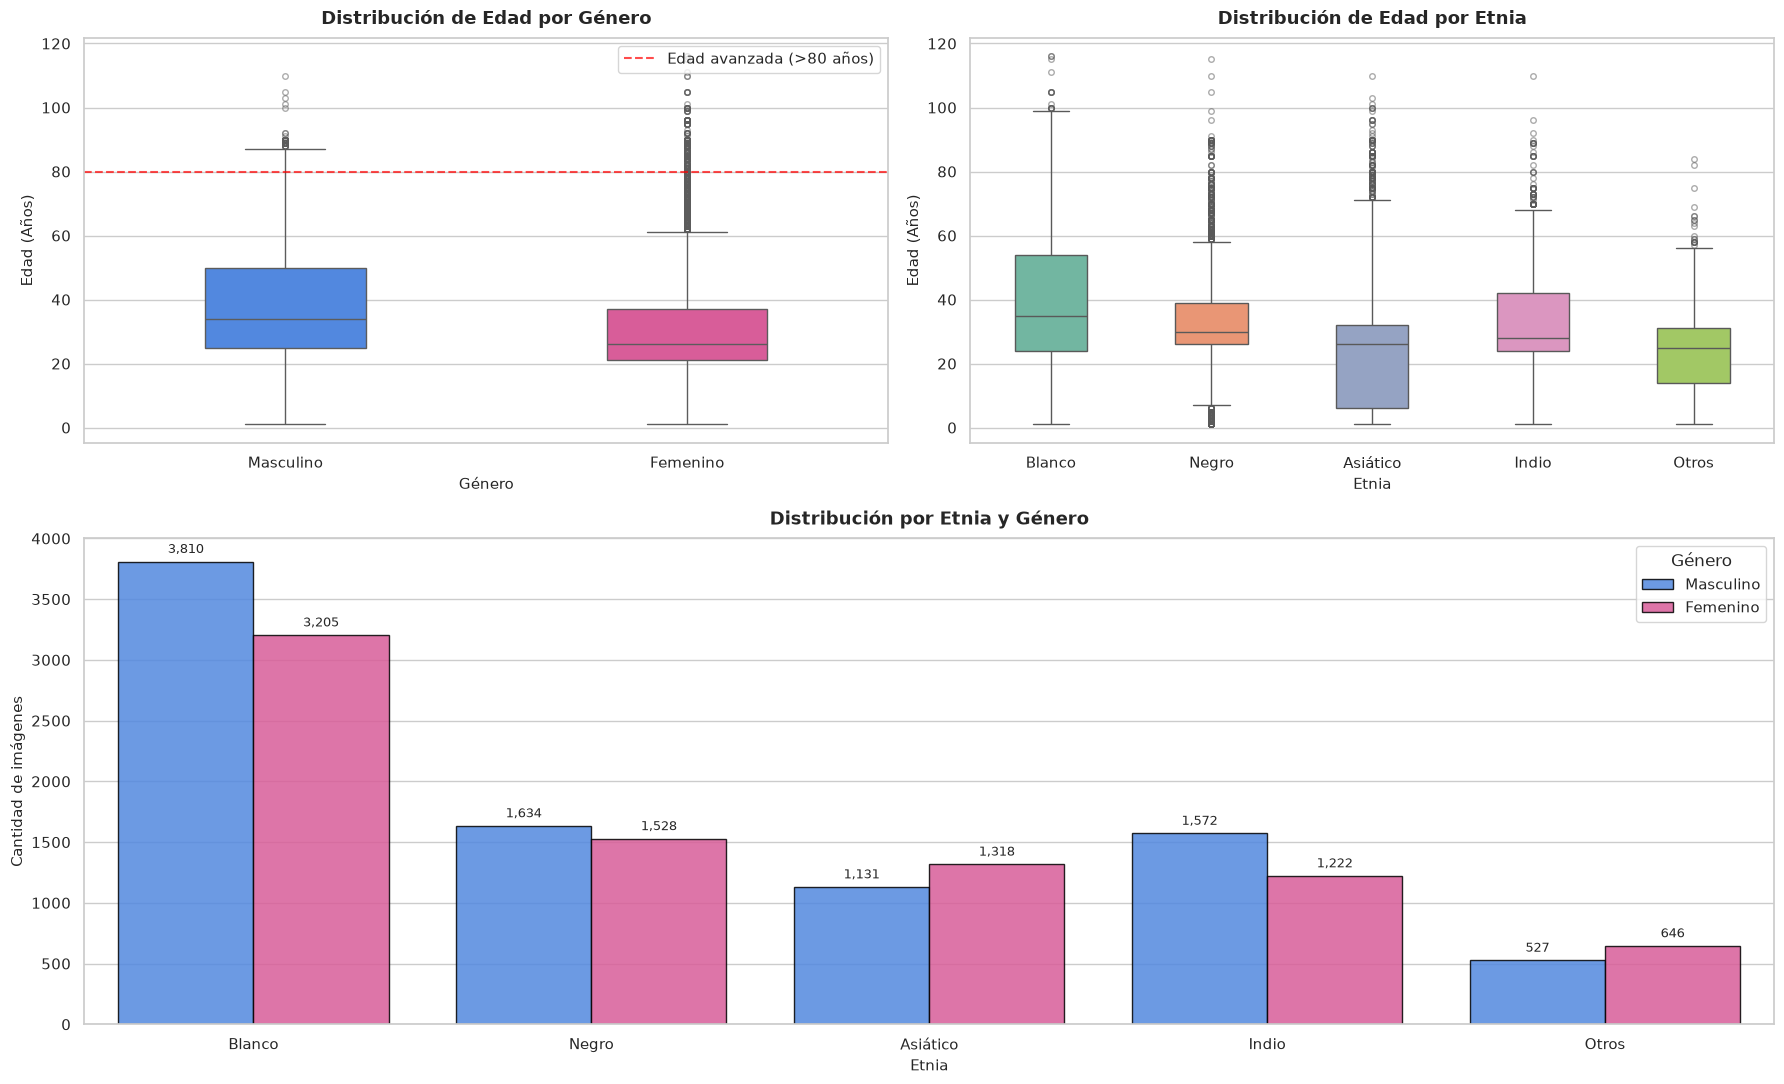

In [82]:
print("--- Estadísticas Descriptivas de Edad (Train Set) ---")
print(train_df["age"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

# Correlación entre Edad y Género
corr = train_df[["age", "gender"]].corr()
print("\n--- Matriz de Correlación (Edad vs Género) ---")
print(corr)

# Mapeo de etnia para los gráficos
race_map = {0: "Blanco", 1: "Negro", 2: "Asiático", 3: "Indio", 4: "Otros"}
train_df["race_label"] = train_df["race"].map(race_map)

# Configurar figura con rejilla: 2 gráficos arriba y 1 ancho abajo
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.2])

# Gráfico superior izquierdo: Boxplot de edad por género
ax1 = fig.add_subplot(gs[0, 0])
sns.boxplot(
    data=train_df,
    x="gender_label",
    y="age",
    palette={"Masculino": "#3b82f6", "Femenino": "#ec4899"},
    width=0.4,
    flierprops=dict(marker="o", markersize=4, alpha=0.5),
    ax=ax1
)
ax1.set_title("Distribución de Edad por Género", fontsize=13, weight="bold", pad=10)
ax1.set_xlabel("Género", fontsize=11)
ax1.set_ylabel("Edad (Años)", fontsize=11)
ax1.axhline(80, color="red", linestyle="--", alpha=0.7, label="Edad avanzada (>80 años)")
ax1.legend(loc="upper right")

# Gráfico superior derecho: Boxplot de edad por etnia
ax2 = fig.add_subplot(gs[0, 1])
sns.boxplot(
    data=train_df,
    x="race_label",
    y="age",
    order=["Blanco", "Negro", "Asiático", "Indio", "Otros"],
    palette="Set2",
    width=0.45,
    flierprops=dict(marker="o", markersize=4, alpha=0.5),
    ax=ax2
)
ax2.set_title("Distribución de Edad por Etnia", fontsize=13, weight="bold", pad=10)
ax2.set_xlabel("Etnia", fontsize=11)
ax2.set_ylabel("Edad (Años)", fontsize=11)

# Gráfico inferior: Conteo por etnia y género a lo ancho
ax3 = fig.add_subplot(gs[1, :])
sns.countplot(
    data=train_df,
    x="race_label",
    hue="gender_label",
    palette={"Masculino": "#3b82f6", "Femenino": "#ec4899"},
    order=["Blanco", "Negro", "Asiático", "Indio", "Otros"],
    edgecolor="black",
    alpha=0.85,
    ax=ax3
)
ax3.set_title("Distribución por Etnia y Género", fontsize=13, weight="bold", pad=10)
ax3.set_xlabel("Etnia", fontsize=11)
ax3.set_ylabel("Cantidad de imágenes", fontsize=11)
ax3.legend(title="Género")

# Anotar la cantidad sobre cada barra
for p in ax3.patches:
    altura = p.get_height()
    if altura > 0:
        ax3.annotate(
            f"{int(altura):,}",
            xy=(p.get_x() + p.get_width() / 2.0, altura),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

plt.tight_layout()
plt.show()


### Inspección Visual

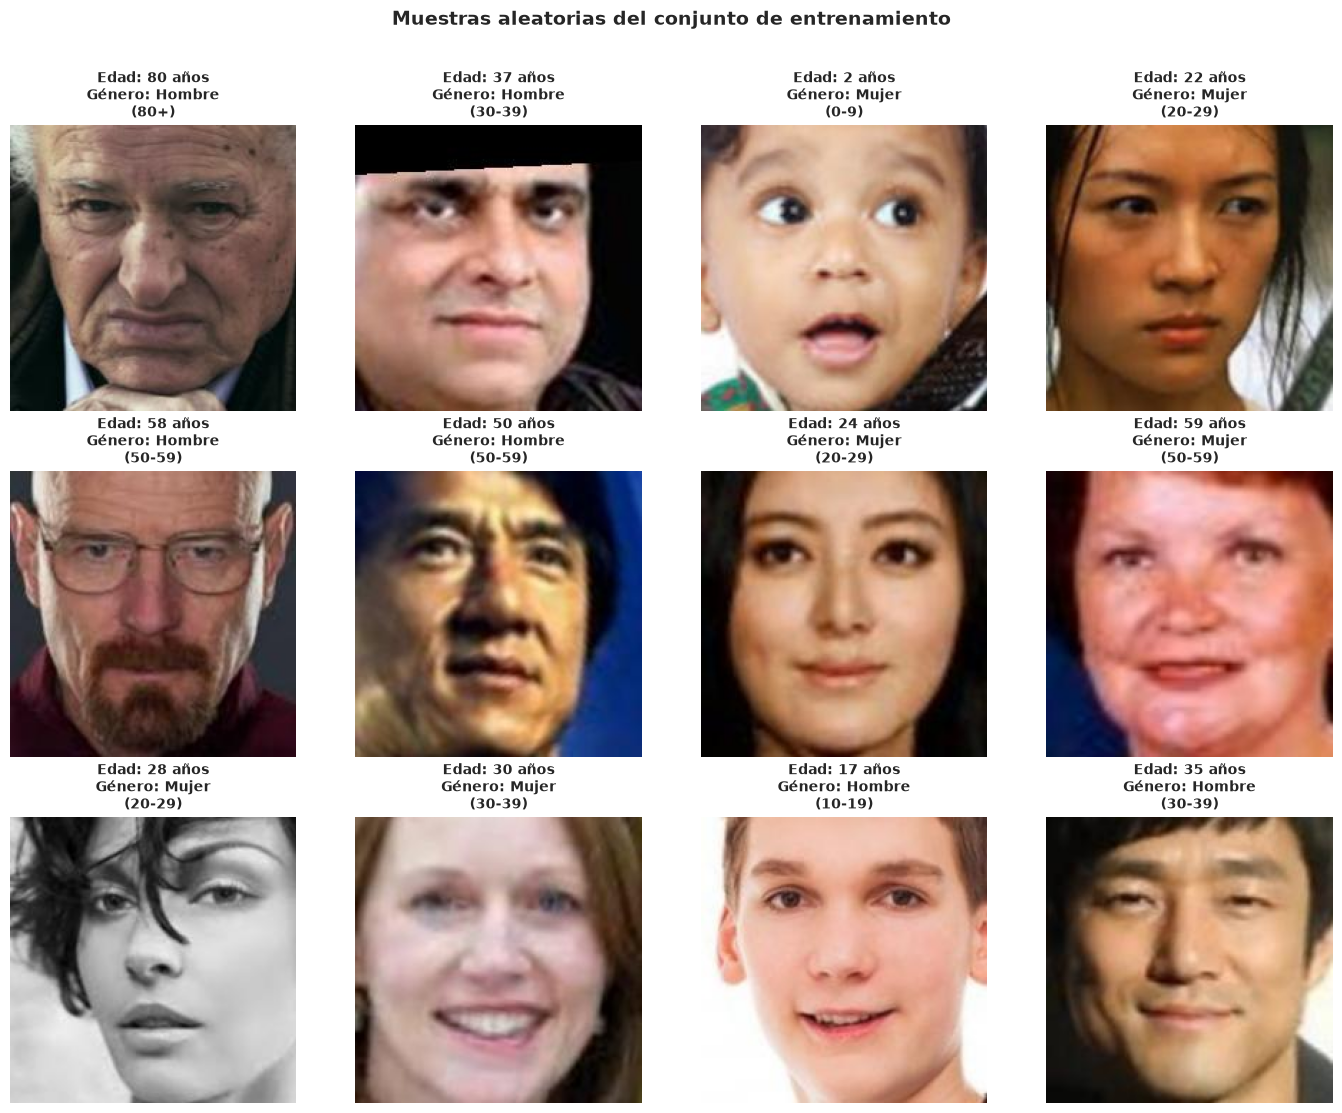

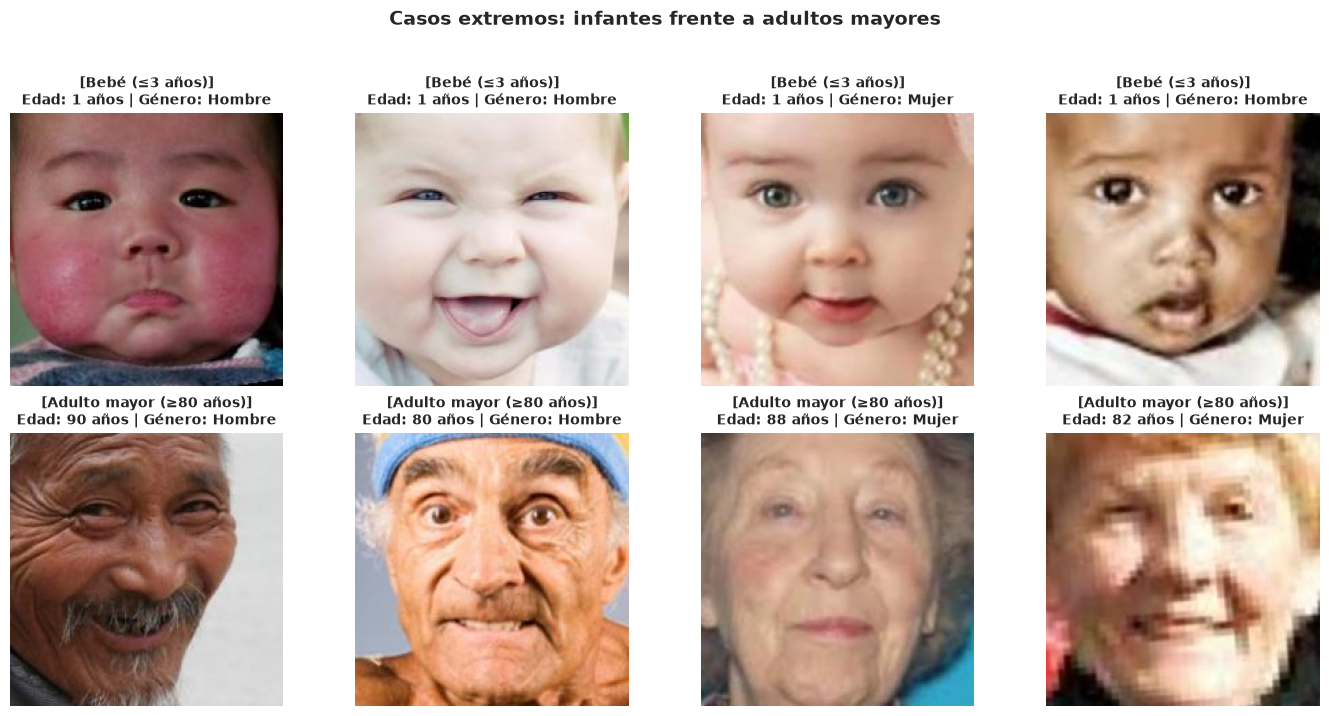

In [83]:
import random

def mostrar_muestras_estratificadas(dataframe, n_muestras=12):
    muestras = dataframe.sample(n=n_muestras, random_state=42)
    
    fig, axes = plt.subplots(3, 4, figsize=(14, 11))
    axes = axes.ravel()

    for i, (_, row) in enumerate(muestras.iterrows()):
        img = Image.open(row["filepath"])
        axes[i].imshow(img)
        axes[i].axis("off")

        genero_txt = "Hombre" if row["gender"] == 0 else "Mujer"
        axes[i].set_title(
            f"Edad: {row['age']} años\nGénero: {genero_txt}\n({row['age_bracket']})",
            fontsize=10, weight="bold"
        )

    plt.suptitle("Muestras aleatorias del conjunto de entrenamiento", fontsize=14, weight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# Comparación visual de casos extremos (bebés y adultos mayores)
def mostrar_casos_extremos(dataframe, n_por_grupo=4):
    bebes = dataframe[dataframe["age"] <= 3].sample(n=n_por_grupo, random_state=42)
    ancianos = dataframe[dataframe["age"] >= 80].sample(n=n_por_grupo, random_state=42)
    casos = pd.concat([bebes, ancianos])
    
    fig, axes = plt.subplots(2, n_por_grupo, figsize=(14, 7))
    axes = axes.ravel()

    for i, (_, row) in enumerate(casos.iterrows()):
        img = Image.open(row["filepath"])
        axes[i].imshow(img)
        axes[i].axis("off")

        etiqueta = "Bebé (≤3 años)" if row["age"] <= 3 else "Adulto mayor (≥80 años)"
        genero_txt = "Hombre" if row["gender"] == 0 else "Mujer"
        axes[i].set_title(
            f"[{etiqueta}]\nEdad: {row['age']} años | Género: {genero_txt}",
            fontsize=10, weight="bold"
        )

    plt.suptitle("Casos extremos: infantes frente a adultos mayores", fontsize=14, weight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

mostrar_muestras_estratificadas(train_df)
mostrar_casos_extremos(train_df)


### Conclusiones del análisis exploratorio

El 100% de las imágenes están en RGB y miden $200 \times 200$, por lo que no hace falta redimensionar ni perder calidad interpolando.

* Hay una mediana de 29 años, frente a una media de 33.3 años y una desviación estándar de casi 20 años, con el 50% de la población concentrada entre los 23 y 45 años.
* Que hayan colas pesadas (con mínimos de un año y máximo de 116) nos dice que la función de costo para la edad debería tolerar valores extremos. Si usamos MSE simple, equivocarse por varios años en un anciano eleva el error al cuadrado y descontrola el entrenamiento, por lo que conviene usar una pérdida como Huber Loss (Smooth L1).

La correlación lineal entre edad y género es débil, lo que indica que no hay colinealidad directa. El modelo multitarea no va a predecir una variable en función de la otra de forma lineal, sino que buscará rasgos visuales compartidos en el rostro.

En cuanto a la etnia, la mayoría de los datos corresponden a personas de etnia blanca (~42%), seguidas de negra, asiática e india con alrededor del 20% cada una, y otros (~7%). Aunque la etnia no se predice, al ver la distribución notamos que:
* Para el género esto no afecta, porque dentro de cada etnia los hombres y mujeres están balanceados al 50%.
* Para la edad puede influir un poco en que hay menos fotos de personas mayores en ciertas etnias, pero los rasgos de la cara para estimar la edad se aprovechan de todo el conjunto.

Al ver la grilla de imágenes hay variabilidad en la resolución (algunas tienen nitidez, otras están pixeladas o sobreescaladas), además de diferencias de iluminación, gafas y maquillaje. Esto hace indispensable aplicar data augmentation (volteos, rotaciones leves y cambios de brillo) para que la red no se confunda con esos detalles externos.

En los casos extremos vistos en las muestras:
* En infantes, como los bebés de hasta 4 años, el género es casi imperceptible a nivel facial, lo que representa un reto donde la red tendrá mayor margen de duda.
* En adultos mayores de 80 años la edad se vuelve más difícil de precisar debido a la variabilidad en arrugas, canas y accesorios.


# Modificación

En esta fase se preparan los datos crudos para que las redes convolucionales puedan procesarlos de forma estable y eficiente:

* Se van a mantener las imágenes en su escala estándar ($200 \times 200$).
* Se va a hacer un volteo horizontal aleatorio, válido tanto para edad como para género.
* Se harán rotaciones y traslaciones leves. Con pequeñas perturbaciones de ángulo, para simular inclinaciones sin deformar rasgos de la cara.
* Se van a hacer ajustes sutiles de brillo y contraste, para robustecer la red ante las diferencias de iluminación.
* Estandarización con la media y desviación estándar del dataset.
* Adicionalmente, dado que la edad va de 1 a 116 y la etiqueta de género es binaria (0 y 1), se va a normalizar la edad en el rango [0,1] dividiendo entre 100.


In [84]:
# Dataset provisional sin normalización (solo conversión a tensor en rango [0.0, 1.0])
class StatsDataset(Dataset):
    def __init__(self, df, img_size=200):
        self.df = df.reset_index(drop=True)
        self.transform = transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.ToTensor()
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = self.df.iloc[idx]['filepath']
        img = Image.open(path).convert('RGB')
        return self.transform(img)

# Loader temporal para procesar en bloques
stats_loader = DataLoader(
    StatsDataset(train_df, img_size=200),
    batch_size=128,
    shuffle=False,
    num_workers=2
)

# Acumuladores de primer y segundo momento
pixel_sum = torch.zeros(3)
pixel_squared_sum = torch.zeros(3)
total_pixel_count = 0

for batch in tqdm(stats_loader, desc="Calculando media y desviación estándar"):
    # batch shape: [B, C, H, W]
    b, c, h, w = batch.shape
    num_pixels = b * h * w
    total_pixel_count += num_pixels

    # Suma por canales a lo largo de las dimensiones de batch, alto y ancho
    pixel_sum += batch.sum(dim=[0, 2, 3])
    pixel_squared_sum += (batch ** 2).sum(dim=[0, 2, 3])

# Media E[X]
custom_mean = pixel_sum / total_pixel_count

# Varianza Var(X) = E[X^2] - (E[X])^2 -> Desviación Estándar = sqrt(Var)
custom_std = torch.sqrt((pixel_squared_sum / total_pixel_count) - (custom_mean ** 2))

custom_mean = custom_mean.tolist()
custom_std = custom_std.tolist()

print(f"\nMedia calculada (Train):  [{custom_mean[0]:.4f}, {custom_mean[1]:.4f}, {custom_mean[2]:.4f}]")
print(f"Desv. Estándar (Train):   [{custom_std[0]:.4f}, {custom_std[1]:.4f}, {custom_std[2]:.4f}]")

Calculando media y desviación estándar: 100%|██████████| 130/130 [00:15<00:00,  8.42it/s]


Media calculada (Train):  [0.5966, 0.4566, 0.3907]
Desv. Estándar (Train):   [0.2591, 0.2315, 0.2270]


Ahora que se tienen la media y la varianza, se aplica toda esta data augmentation al dataset con un pipeline:

In [85]:
IMAGE_SIZE = 200

# Data Augmentation y Normalización propia para Entrenamiento
train_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), #redimension
    transforms.RandomHorizontalFlip(p=0.5), # flips horizontales
    transforms.RandomRotation(degrees=10), # rotacion random
    transforms.ColorJitter(brightness=0.15, contrast=0.15), # Contraste
    transforms.ToTensor(),
    transforms.Normalize(mean=custom_mean, std=custom_std) # Normalización
])

# Transformaciones deterministas para Validación y Prueba
val_test_transforms = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=custom_mean, std=custom_std)
])

# Dataset definitivo
class UTKFaceDataset(Dataset):
    def __init__(self, df, transform=None, normalize_age=True):
        self.df = df.reset_index(drop=True)
        self.transform = transform
        self.normalize_age = normalize_age

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row['filepath']).convert('RGB')

        if self.transform:
            image = self.transform(image)

        gender = torch.tensor(row['gender'], dtype=torch.float32)
        raw_age = float(row['age'])
        age = raw_age / 100.0 if self.normalize_age else raw_age
        age = torch.tensor(age, dtype=torch.float32)

        return image, {
            'age': age,
            'gender': gender,
            'raw_age': torch.tensor(raw_age, dtype=torch.float32)
        }

# Instanciar Datasets y Loaders
BATCH_SIZE = 64
NUM_WORKERS = 2

train_dataset = UTKFaceDataset(train_df, transform=train_transforms, normalize_age=True)
val_dataset   = UTKFaceDataset(val_df,   transform=val_test_transforms, normalize_age=True)
test_dataset  = UTKFaceDataset(test_df,  transform=val_test_transforms, normalize_age=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# Modelado

In [86]:
# -------------------------------------------------------------
# 1. Bloque Convolucional Básico (Conv2d + BatchNorm + ReLU)
# -------------------------------------------------------------
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

    def forward(self, x):
        return self.block(x)

# -------------------------------------------------------------
# 2. Backbone Convolucional Base
# -------------------------------------------------------------
class FeatureExtractorBackbone(nn.Module):
    def __init__(self):
        super(FeatureExtractorBackbone, self).__init__()
        self.features = nn.Sequential(
            ConvBlock(3, 32),     # 200x200 -> 100x100
            ConvBlock(32, 64),    # 100x100 -> 50x50
            ConvBlock(64, 128),   # 50x50   -> 25x25
            ConvBlock(128, 256)   # 25x25   -> 12x12
        )
        self.gap = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):
        x = self.features(x)
        x = self.gap(x)
        x = torch.flatten(x, 1)  # Salida: [B, 256]
        return x

# -------------------------------------------------------------
# 3. Modelo 1: Especializado en Edad (Regresión)
# -------------------------------------------------------------
class AgeEstimationModel(nn.Module):
    def __init__(self):
        super(AgeEstimationModel, self).__init__()
        self.backbone = FeatureExtractorBackbone()
        self.age_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1)  # Salida escalar (edad normalizada)
        )

    def forward(self, x):
        features = self.backbone(x)
        age = self.age_head(features)
        return age.squeeze(1)

# -------------------------------------------------------------
# 4. Modelo 2: Especializado en Género (Clasificación Binaria)
# -------------------------------------------------------------
class GenderClassificationModel(nn.Module):
    def __init__(self):
        super(GenderClassificationModel, self).__init__()
        self.backbone = FeatureExtractorBackbone()
        self.gender_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1)  # Logit para BCEWithLogitsLoss
        )

    def forward(self, x):
        features = self.backbone(x)
        gender_logit = self.gender_head(features)
        return gender_logit.squeeze(1)

# -------------------------------------------------------------
# 5. Modelo 3: Multitarea (Backbone compartido + Bifurcación)
# -------------------------------------------------------------
class MultiTaskFaceModel(nn.Module):
    def __init__(self):
        super(MultiTaskFaceModel, self).__init__()
        self.backbone = FeatureExtractorBackbone()

        # Cabeza de Edad
        self.age_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1)
        )

        # Cabeza de Género
        self.gender_head = nn.Sequential(
            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.4),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        features = self.backbone(x)
        pred_age = self.age_head(features).squeeze(1)
        pred_gender = self.gender_head(features).squeeze(1)
        return pred_age, pred_gender

### Prueba de paso hacia adelante

In [87]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo de cómputo:", device)

# Tensor de prueba con la forma de un batch [B=4, C=3, H=200, W=200]
dummy_input = torch.randn(4, 3, 200, 200).to(device)

# Instanciación
model_age = AgeEstimationModel().to(device)
model_gender = GenderClassificationModel().to(device)
model_multi = MultiTaskFaceModel().to(device)

# Comprobación de salidas
out_age = model_age(dummy_input)
out_gender = model_gender(dummy_input)
multi_age, multi_gender = model_multi(dummy_input)

print("\n--- Verificación de Dimensiones de Salida ---")
print("Salida Modelo Edad:       ", out_age.shape)           # Esperado: torch.Size([4])
print("Salida Modelo Género:     ", out_gender.shape)        # Esperado: torch.Size([4])
print("Salida Multi (Edad):      ", multi_age.shape)         # Esperado: torch.Size([4])
print("Salida Multi (Género):    ", multi_gender.shape)      # Esperado: torch.Size([4])

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("\n--- Conteo de Parámetros Entrenables ---")
print(f"Modelo Edad Dedicado:   {count_parameters(model_age):,} parámetros")
print(f"Modelo Género Dedicado: {count_parameters(model_gender):,} parámetros")
print(f"Modelo Multitarea:      {count_parameters(model_multi):,} parámetros")

Dispositivo de cómputo: cuda

--- Verificación de Dimensiones de Salida ---
Salida Modelo Edad:        torch.Size([4])
Salida Modelo Género:      torch.Size([4])
Salida Multi (Edad):       torch.Size([4])
Salida Multi (Género):     torch.Size([4])

--- Conteo de Parámetros Entrenables ---
Modelo Edad Dedicado:   1,206,497 parámetros
Modelo Género Dedicado: 1,206,497 parámetros
Modelo Multitarea:      1,239,778 parámetros


# Referencias

[1] https://www.geeksforgeeks.org/deep-learning/how-to-process-multiple-losses-in-pytorch/
